# Task 1.1: the real circuit, memory + buffer

**In plain words.** In hardware, pair leakage is engineered with a second, very leaky resonator (the *buffer*). The one-mode model of Task 1.0 assumes the buffer empties instantly. Here it doesn't:
$g_2/\kappa_b = 0.29$ and $\epsilon_d/\kappa_b = 1.29$, so the condition $\kappa_b \gg g_2, \epsilon_d$ fails.

**Prediction before simulating:** the buffer briefly fills up, keeps feeding photon pairs after the memory reaches $\alpha^2$, so the memory **overshoots** and rings down. In steady state the buffer is empty, which forces $a^2=\alpha^2$, so it still settles at 4.41.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath('..'))
os.chdir(os.path.abspath('..'))          # run from the repo root so figures/ and results/ resolve
from IPython.display import Image, display
show = lambda name, w=900: display(Image(f'figures/{name}.png', width=w))
load = lambda name: json.load(open(f'results/{name}.json'))

saved /home/claude/duquantum-cat-qubit/figures/task_1_1_inflation.png


saved /home/claude/duquantum-cat-qubit/figures/task_1_1_wigner.png
{'Na': 32, 'Nb': 12, 'peak_na': 6.894411732563246, 't_peak_us': 0.23, 'overshoot_over_alpha2': 1.5633586695154753, 'settle_1pct_us': 1.07, 'steady_na': 4.402615556547587, 'peak_nb': 1.9915204899995718, 't_peak_nb_us': 0.13, 'max_top2_a': 1.3618818507777727e-05, 'max_top_b': 0.00016920820976138693, 'starter_peak_na': 6.114517213948512, 'starter_max_top_b': 0.04624162894759327, 'g2_over_kappab': 0.2934615384615385, 'epsd_over_kappab': 1.2941653846153847}
saved /home/claude/duquantum-cat-qubit/results/task_1_1.json


{'Na': 32,
 'Nb': 12,
 'peak_na': 6.894411732563246,
 't_peak_us': 0.23,
 'overshoot_over_alpha2': 1.5633586695154753,
 'settle_1pct_us': 1.07,
 'steady_na': 4.402615556547587,
 'peak_nb': 1.9915204899995718,
 't_peak_nb_us': 0.13,
 'max_top2_a': 1.3618818507777727e-05,
 'max_top_b': 0.00016920820976138693,
 'starter_peak_na': 6.114517213948512,
 'starter_max_top_b': 0.04624162894759327,
 'g2_over_kappab': 0.2934615384615385,
 'epsd_over_kappab': 1.2941653846153847}

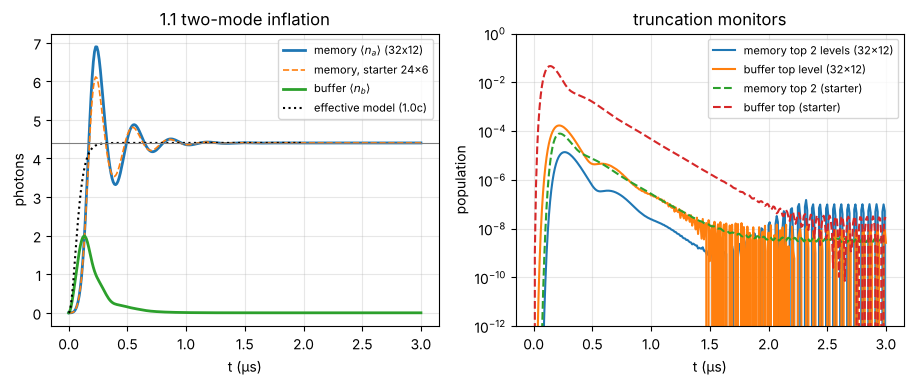

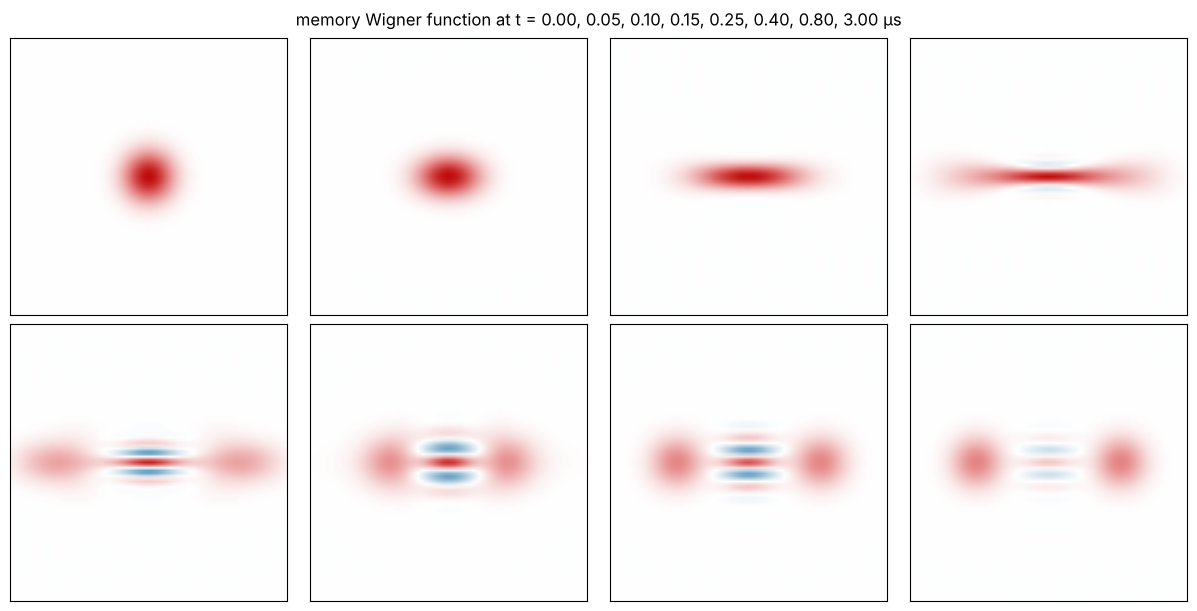

In [2]:
from src import config as C
from tasks import task_1_1
task_1_1.main(C.NA, C.NB)
load('task_1_1')

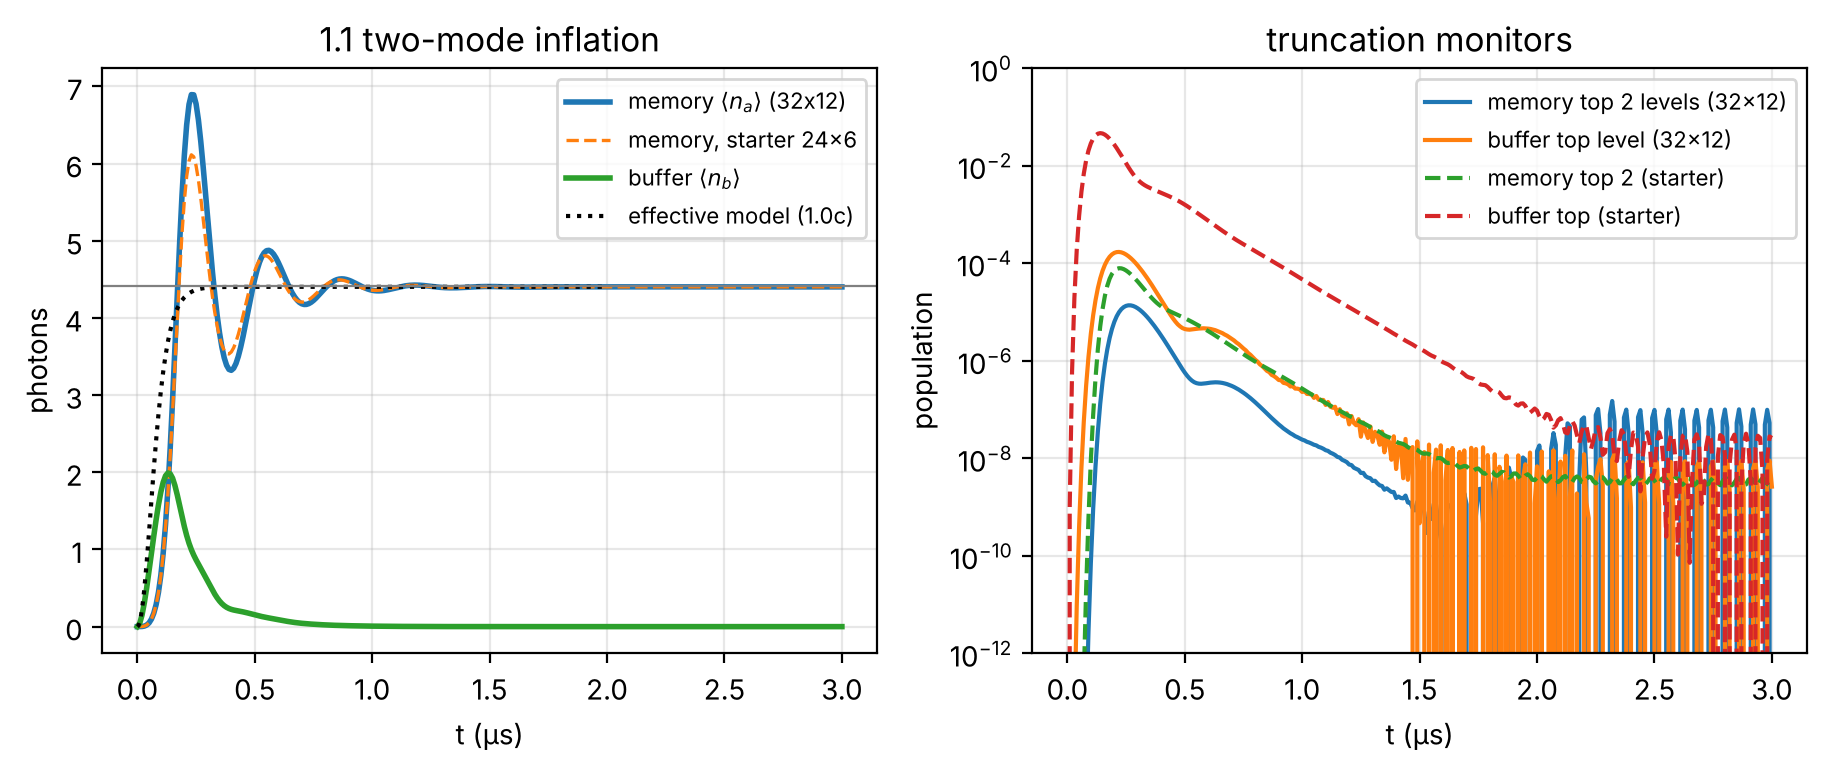

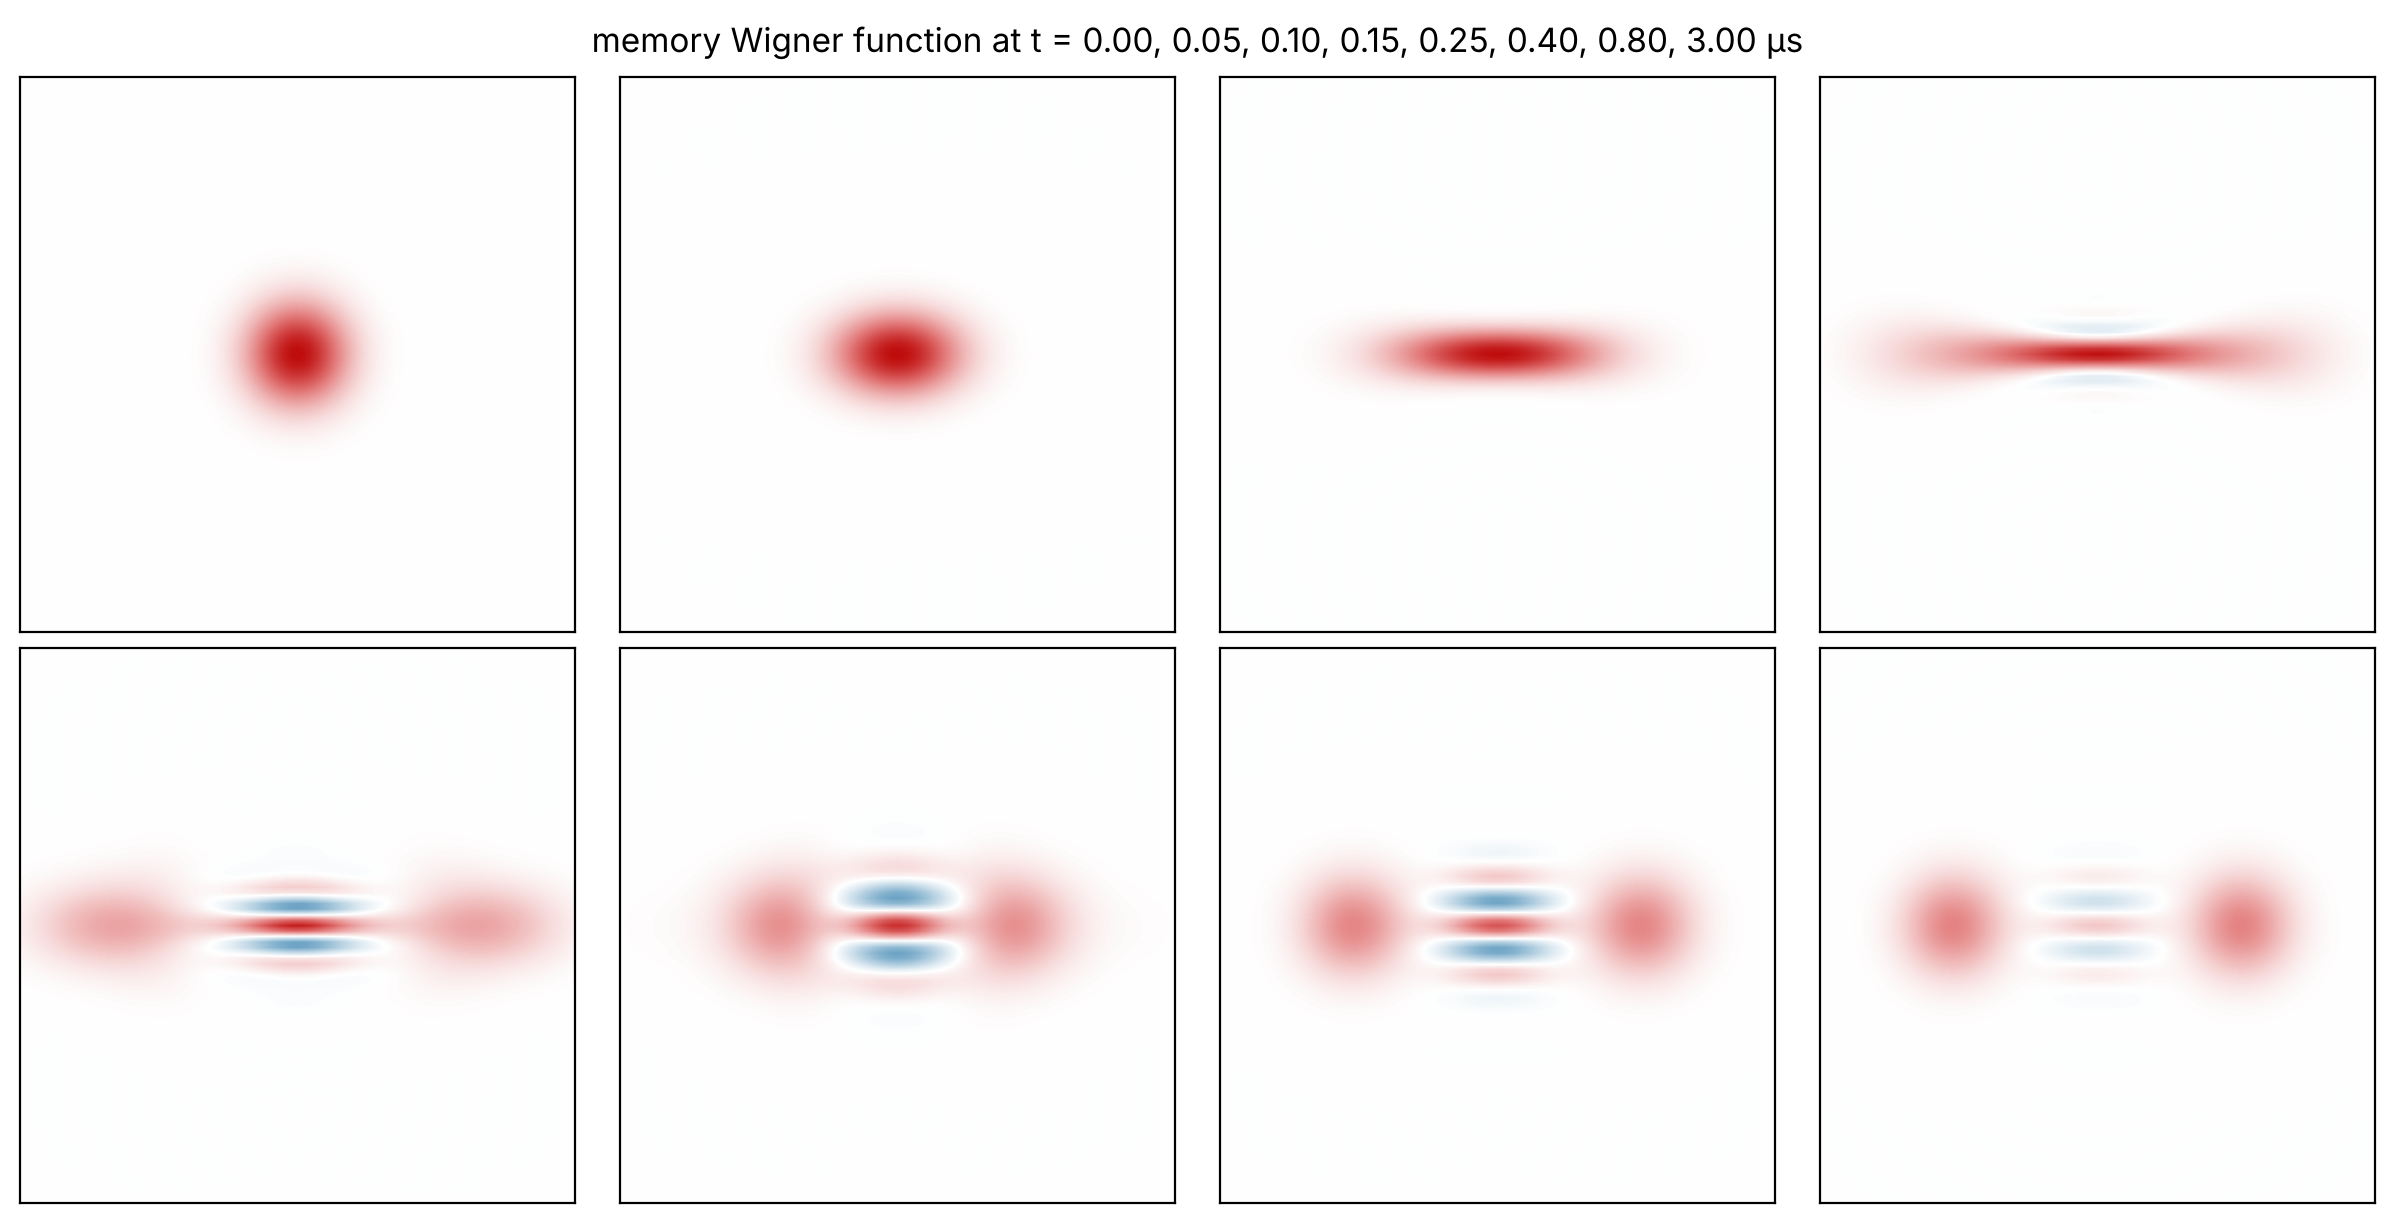

In [3]:
show('task_1_1_inflation'); show('task_1_1_wigner')

**Reading the plots.** Left: the two-mode memory (solid) overshoots to ~1.56 α² and settles within 1% after ~1 µs, while the effective model (dotted) rises smoothly. The starter 24×6 truncation (dashed) underestimates the peak. Right: populations in the top Fock levels. The starter buffer truncation leaks several percent into its top level during the transient, which is the problem Task 1.2 pins down.